# Лабораторная 2. Классификация
Предсказываем выживание на Титанике: `1` - выжил, `0` - нет.
Данные: [Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset), CSV лежит рядом.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay, make_scorer)

seed = 228
plt.rcParams.update({'figure.figsize': (8, 4), 'font.size': 10})
pd.set_option('display.max_columns', 15)
data_path = Path('Titanic-Dataset.csv')
if not data_path.exists():
    data_path = Path('classification/solution/Titanic-Dataset.csv')
data = pd.read_csv(data_path)
display(data.head())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 1. Что в данных

Размер: (891, 12)
Полных дубликатов: 0
Повторов PassengerId: 0


,тип,пропуски,уникальных
PassengerId,int64,0,891
Survived,int64,0,2
Pclass,int64,0,3
Name,str,0,891
Sex,str,0,2
Age,float64,177,88
SibSp,int64,0,7
Parch,int64,0,7
Ticket,str,0,681
Fare,float64,0,248


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


,число,доля
Survived,,
0,549,0.616
1,342,0.384


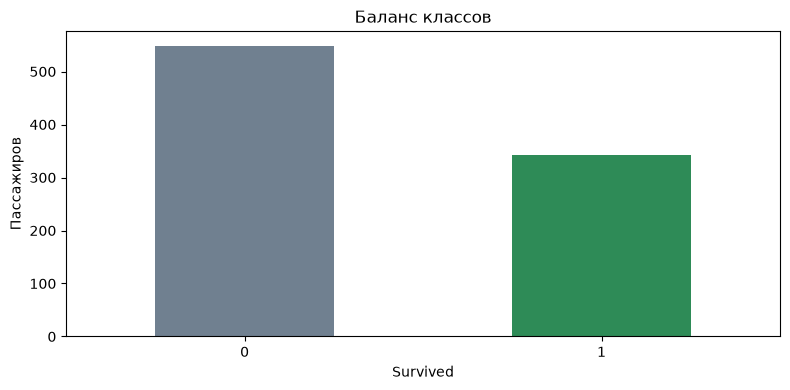

In [2]:
print('Размер:', data.shape)
display(pd.DataFrame({'тип': data.dtypes.astype(str), 'пропуски': data.isna().sum(),
                      'уникальных': data.nunique()}))
print('Полных дубликатов:', data.duplicated().sum())
print('Повторов PassengerId:', data.PassengerId.duplicated().sum())
display(data.describe().round(2))
balance = data.Survived.value_counts().sort_index()
display(pd.DataFrame({'число': balance, 'доля': balance / len(data)}).round(3))
balance.plot.bar(rot=0, color=['slategray', 'seagreen'])
plt.xlabel('Survived'); plt.ylabel('Пассажиров'); plt.title('Баланс классов')
plt.tight_layout(); plt.show()

891 пассажир, 12 столбцов, выжили 38%. Дубликатов строк и ID нет.
Пропуски: Age - 177, Cabin - 687, Embarked - 2.
Cabin убрал из-за пропусков, PassengerId, Name и Ticket - чтобы не запоминать пассажиров.
Survived в признаки не включаю.

## 2. Подготовка
Делю 80/20 со стратификацией и фиксированным seed: доли классов сохраняются.
Зависимости дальше смотрю на train, test оставляю для финала.

Train: 712 Test: 179
Доля выживших: 0.383 0.385


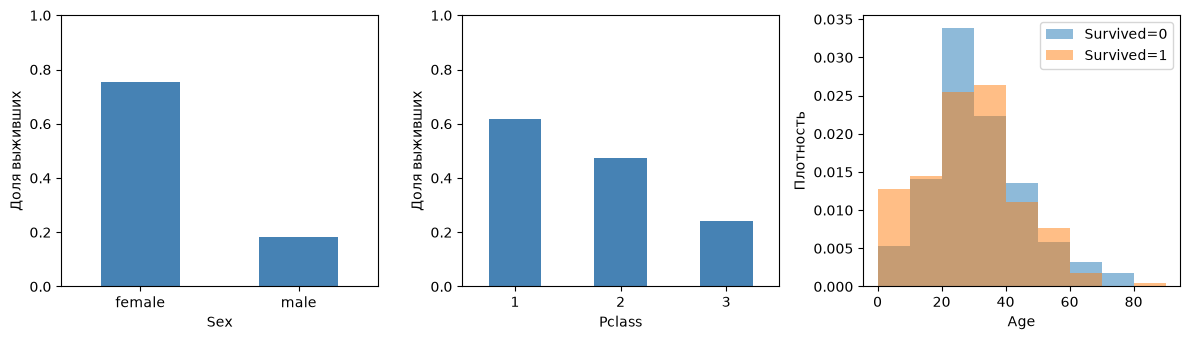

,size,mean
Sex,,
female,249,0.755
male,463,0.184


,size,mean
Pclass,,
1,176,0.619
2,148,0.473
3,388,0.242


In [3]:
numeric = ['Age', 'SibSp', 'Parch', 'Fare']
categorical = ['Pclass', 'Sex', 'Embarked']
features = numeric + categorical
X = data[features]
y = data.Survived
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y)
train = X_train.join(y_train)
print('Train:', len(X_train), 'Test:', len(X_test))
print('Доля выживших:', round(y_train.mean(), 3), round(y_test.mean(), 3))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for col, ax in zip(['Sex', 'Pclass'], axes[:2]):
    train.groupby(col).Survived.mean().plot.bar(ax=ax, rot=0, color='steelblue')
    ax.set(xlabel=col, ylabel='Доля выживших', ylim=(0, 1))
for label, group in train.groupby('Survived'):
    axes[2].hist(group.Age.dropna(), bins=np.arange(0, 91, 10), alpha=0.5,
                 density=True, label=f'Survived={label}')
axes[2].set(xlabel='Age', ylabel='Плотность'); axes[2].legend()
plt.tight_layout(); plt.show()
display(train.groupby('Sex').Survived.agg(['size', 'mean']).round(3))
display(train.groupby('Pclass').Survived.agg(['size', 'mean']).round(3))

Женщины и пассажиры первого класса выживали чаще. По возрасту классы сильно пересекаются.

Числа заполняю медианой, она устойчива к большим Fare. Категории - модой, затем one-hot.
Pclass считаю категорией. Для SVM и KNN нужен StandardScaler: иначе Fare задавит другие признаки
в расстояниях. Деревьям он не нужен. Все преобразования внутри Pipeline обучаются только на train,
при CV - на обучающей части фолда.

In [4]:
def preprocessing(scale=False):
    steps = [('fill', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale', StandardScaler()))
    return ColumnTransformer([
        ('num', Pipeline(steps), numeric),
        ('cat', Pipeline([
            ('fill', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical)
    ], verbose_feature_names_out=False)

def pipeline(model, scale=False):
    return Pipeline([('prep', preprocessing(scale)), ('model', model)])

cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X_train, y_train))
scoring = {'Accuracy': 'accuracy',
           'Precision': make_scorer(precision_score, zero_division=0),
           'Recall': 'recall', 'F1': 'f1'}

models = {'Dummy': pipeline(DummyClassifier(strategy='most_frequent'))}
fitted, cv_rows = {}, []

def evaluate_train(name, model):
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({'Модель': name, 'F1-CV': scores['test_F1'].mean(),
                    'std-CV': scores['test_F1'].std()})
    fitted[name] = clone(model).fit(X_train, y_train)

evaluate_train('Dummy', models['Dummy'])
display(pd.DataFrame(cv_rows).set_index('Модель').round(3))

,F1-CV,std-CV
Модель,,
Dummy,0.0,0.0


Dummy всегда предсказывает гибель: F1 = 0, выживших не находит.
Accuracy при этом около 0.615. Поэтому основная метрика - F1 для класса 1, нужен F1 > 0.70.

## 3. Модели
Дерево, лес, бустинг, SVM и KNN. Параметры задал заранее, сравниваю на одинаковых пяти фолдах train.

In [5]:
models.update({
    'Decision Tree': pipeline(DecisionTreeClassifier(max_depth=5, min_samples_leaf=5,
                                                     random_state=seed)),
    'Random Forest': pipeline(RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                     random_state=seed, n_jobs=1)),
    'Gradient Boosting': pipeline(GradientBoostingClassifier(n_estimators=150,
                                  learning_rate=0.05, max_depth=2, random_state=seed)),
    'SVM': pipeline(SVC(C=3), scale=True),
    'KNN': pipeline(KNeighborsClassifier(n_neighbors=9), scale=True)
})
for name, model in list(models.items())[1:]:
    evaluate_train(name, model)

cv_results = pd.DataFrame(cv_rows).set_index('Модель')
best_name = cv_results['F1-CV'].idxmax()
best_model = fitted[best_name]
display(cv_results.sort_values('F1-CV', ascending=False).round(3))
print('Выбрал по CV:', best_name)

Выбрал по CV: Gradient Boosting


,F1-CV,std-CV
Модель,,
Gradient Boosting,0.757,0.041
Random Forest,0.757,0.043
SVM,0.742,0.040
Decision Tree,0.740,0.033
KNN,0.729,0.046
Dummy,0.000,0.000


## 4. Итог на test
Победитель уже выбран по CV. Теперь считаю итоговые метрики на одном test. Пороги предсказаний стандартные.

,Accuracy,Precision,Recall,F1,F1-train,F1-CV,std-CV,F1 > 0.70
Модель,,,,,,,,
Dummy,0.615,0.000,0.000,0.000,0.000,0.000,0.000,False
Decision Tree,0.782,0.742,0.667,0.702,0.794,0.740,0.033,True
Random Forest,0.821,0.776,0.754,0.765,0.869,0.757,0.043,True
Gradient Boosting,0.810,0.787,0.696,0.738,0.801,0.757,0.041,True
SVM,0.816,0.833,0.652,0.732,0.783,0.742,0.040,True
KNN,0.810,0.778,0.710,0.742,0.780,0.729,0.046,True


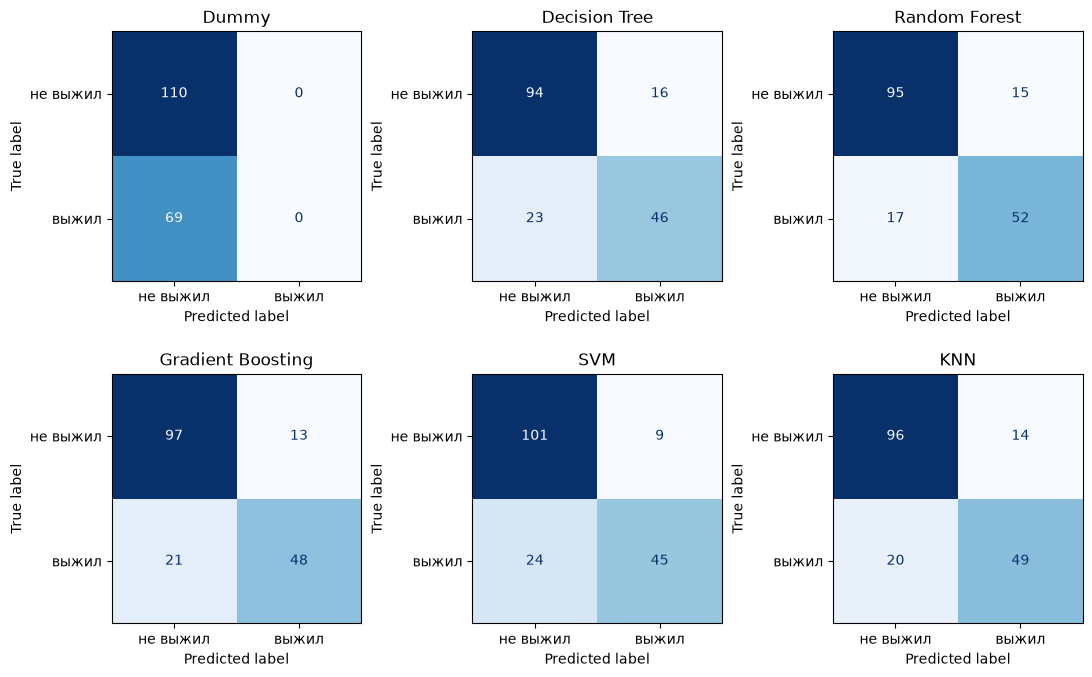

,FP,FN
Dummy,0,69
Decision Tree,16,23
Random Forest,15,17
Gradient Boosting,13,21
SVM,9,24
KNN,14,20


In [6]:
predictions, rows = {}, []
for name, model in fitted.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    rows.append({'Модель': name,
                 'Accuracy': accuracy_score(y_test, pred),
                 'Precision': precision_score(y_test, pred, zero_division=0),
                 'Recall': recall_score(y_test, pred, zero_division=0),
                 'F1': f1_score(y_test, pred, zero_division=0),
                 'F1-train': f1_score(y_train, model.predict(X_train), zero_division=0)})
results = pd.DataFrame(rows).set_index('Модель').join(cv_results)
results['F1 > 0.70'] = results.F1 > 0.70
display(results.round(3))

fig, axes = plt.subplots(2, 3, figsize=(11, 7))
for (name, pred), ax in zip(predictions.items(), axes.flat):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=[0, 1],
        display_labels=['не выжил', 'выжил'], ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

errors_by_model = pd.DataFrame({name: {'FP': confusion_matrix(y_test, pred)[0, 1],
                                      'FN': confusion_matrix(y_test, pred)[1, 0]}
                                for name, pred in predictions.items()}).T
display(errors_by_model)

По CV выбрал бустинг: F1 = 0.757, лес отстал меньше чем на 0.001. Уверенного победителя нет.
На test F1 бустинга = 0.738, леса = 0.765; выбор после test не меняю.
Все пять моделей прошли 0.70. У дерева F1-train = 0.794 против F1-test = 0.702: есть переобучение.

FP - предсказали выживание, человек погиб. FN - предсказали гибель, человек выжил.
Dummy дает только FN, остальные ошибаются в обе стороны.
Лес усредняет деревья, бустинг исправляет ошибки последовательно. SVM строит нелинейную границу,
KNN голосует по соседям. Эти различия могут объяснять разницу качества.

## 5. Важность признаков
Суммирую важности one-hot столбцов обратно по исходному признаку, чтобы сравнение было понятнее.

Топ-3:
Decision Tree : Sex, Pclass, Fare
Random Forest : Sex, Fare, Age
Gradient Boosting : Sex, Pclass, Age


,Decision Tree,Random Forest,Gradient Boosting
Age,0.051,0.177,0.122
SibSp,0.067,0.049,0.041
Parch,0.001,0.028,0.003
Fare,0.137,0.203,0.059
Pclass,0.171,0.116,0.183
Sex,0.567,0.390,0.581
Embarked,0.006,0.037,0.011


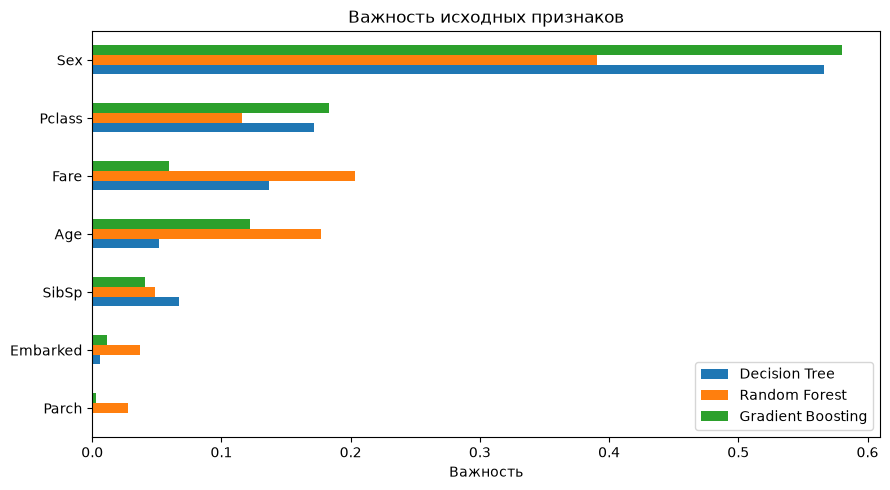

In [7]:
importance = {}
for name in ['Decision Tree', 'Random Forest', 'Gradient Boosting']:
    model = fitted[name]
    names = model['prep'].get_feature_names_out()
    raw = pd.Series(model['model'].feature_importances_, index=names)
    groups = [next(col for col in features if f == col or f.startswith(col + '_')) for f in names]
    importance[name] = raw.groupby(groups).sum().reindex(features)
importance = pd.DataFrame(importance)
display(importance.round(3))
importance.loc[importance.mean(axis=1).sort_values().index].plot.barh(figsize=(9, 5))
plt.xlabel('Важность'); plt.ylabel(''); plt.title('Важность исходных признаков')
plt.tight_layout(); plt.show()
print('Топ-3:')
for name in importance:
    print(name, ':', ', '.join(importance[name].nlargest(3).index))

Sex первый у всех. Дальше: дерево - Pclass и Fare, лес - Fare и Age, бустинг - Pclass и Age.
Пол и класс выделялись еще на графиках train. Возраст и цена тоже помогают.

Важность не доказывает причину выживания: это вклад в разбиения модели.
Признаки связаны, например Fare и Pclass. Важности деревьев могут быть смещены
в пользу числовых признаков с большим числом порогов.

## 6. Ошибки лучшей по CV модели

Gradient Boosting : TN = 97 FP = 13 FN = 21 TP = 48
Sex
Pclass
AgeGroup


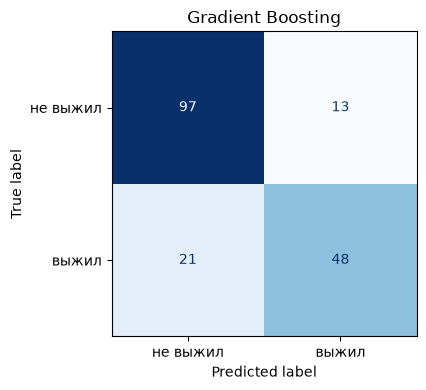

,N,errors,error_rate,FP,FN
Sex,,,,,
female,65,14,0.215,12,2
male,114,20,0.175,1,19


,N,errors,error_rate,FP,FN
Pclass,,,,,
1,40,11,0.275,2,9
2,36,1,0.028,1,0
3,103,22,0.214,10,12


,N,errors,error_rate,FP,FN
AgeGroup,,,,,
до 16,16,3,0.188,3,0
16-39,92,19,0.207,7,12
40+,31,3,0.097,1,2
нет возраста,40,9,0.225,2,7


,Sex,Pclass,Age,Fare,SibSp,Parch,Survived,prediction,тип ошибки
41,female,2,27.0,21.0000,1,0,0,1,FP
828,male,3,NaN,7.7500,0,0,1,0,FN
554,female,3,22.0,7.7750,0,0,1,0,FN
396,female,3,31.0,7.8542,0,0,0,1,FP


In [8]:
pred = predictions[best_name]
tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
print(best_name, ': TN =', tn, 'FP =', fp, 'FN =', fn, 'TP =', tp)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['не выжил', 'выжил'],
                                        cmap='Blues', colorbar=False)
plt.title(best_name); plt.tight_layout(); plt.show()

errors = X_test.join(y_test).copy()
errors['prediction'] = pred
errors['error'] = errors.Survived != pred
errors['FP'] = (errors.Survived == 0) & (pred == 1)
errors['FN'] = (errors.Survived == 1) & (pred == 0)
errors['AgeGroup'] = pd.cut(errors.Age, [0, 16, 40, np.inf], right=False,
                           labels=['до 16', '16-39', '40+']).cat.add_categories('нет возраста').fillna('нет возраста')
for group in ['Sex', 'Pclass', 'AgeGroup']:
    print(group)
    display(errors.groupby(group, observed=True).agg(
        N=('error', 'size'), errors=('error', 'sum'), error_rate=('error', 'mean'),
        FP=('FP', 'sum'), FN=('FN', 'sum')).round(3))

wrong = errors[errors.error].copy()
wrong['тип ошибки'] = np.where(wrong.FP, 'FP', 'FN')
examples = wrong.groupby('тип ошибки', group_keys=False).head(2)
display(examples[['Sex', 'Pclass', 'Age', 'Fare', 'SibSp', 'Parch',
                  'Survived', 'prediction', 'тип ошибки']])

Бустинг чаще пропускает выживших: FN = 21, FP = 13. Доля ошибок выше у женщин: 21.5% против 17.5%.
По классу хуже первый: 11/40 = 27.5%; по возрасту - пропущенный Age: 9/40 = 22.5%.
Группы маленькие, это результат только нашего test.

Примеры по индексам строк:
- 41 и 396: женщины погибли, прогноз 1. Возможно, модель слишком оперлась на пол.
- 828: мужчина третьего класса выжил, прогноз 0. Возраст неизвестен, подставлена медиана.
- 554: женщина 22 лет выжила, прогноз 0. Возможно, повлияли третий класс и дешевый билет.

Это предположения, точную причину по строке не узнать.

Проверка утечки: в модели только семь признаков, без имен, ID, билетов, кают и Survived.
Все преобразования учатся на train. Родственники могли попасть в обе части: проверка на новых
семьях могла бы дать другой результат.

In [9]:
excluded = {'PassengerId', 'Name', 'Ticket', 'Cabin', 'Survived'}
assert excluded.isdisjoint(X.columns)
assert X_train.index.intersection(X_test.index).empty
print('Признаки:', ', '.join(X.columns))
print('Пересечений строк train/test и запрещенных столбцов нет.')

Признаки: Age, SibSp, Parch, Fare, Pclass, Sex, Embarked
Пересечений строк train/test и запрещенных столбцов нет.


## Вывод
Выбрал бустинг по CV. На локальном test F1 = 0.738, порог пройден.
Результат на общем тесте группы пока неизвестен. Пол и класс полезны, но ошибки остаются.